<a href="https://colab.research.google.com/github/lezamajuan97-LZZ/Investigaci-n-de-operaciones/blob/main/Copia_de_simulacion__2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

27 de agosto 2026

Aproximacion de sqrt(2) por Simulación de Montecarlo


valor estimado 1.4142502399999999
valor verdadero 1.4142135623730951
error 3.6677626904735305e-05


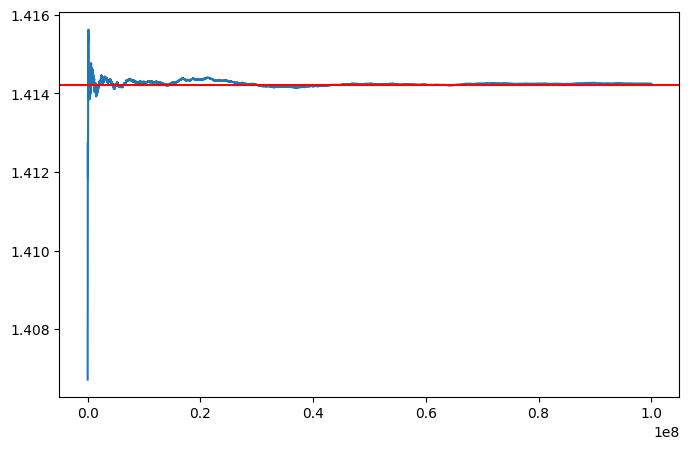

In [ ]:
from random import random
from math import sqrt
import matplotlib.pyplot as plt

n=100000000
m=0
lx=[]
ly=[]

for i in range (n):
  x=1+random()
  if x**2<2:
    m=m+1
  if i>0 and i%5000==0:
    lx.append(i+1)
    ly.append(1+m/(i+1))

print("valor estimado", 1 + m/n);

valor_v=sqrt(2)
valor_t=(1+m/n)
error = abs(valor_v - valor_t)

print("valor verdadero", valor_v);
print("error", error)

plt.figure(figsize=(8,5))
plt.plot(lx,ly)
plt.axhline(sqrt(2),color='red')
plt.show()

In [ ]:
# codigo del profe
from random import random

N=1000000
n=0

for i in range(N):
  r=2*random()
  if r**2<2:
    n=n+1

print(2*n/N)

1.41477


03 de septiembre de 2026


Estimar por simulacion de Montecarlo el coeficiente de correlacion entre w_10 y w_20

scipy
movimiento browniano

In [ ]:
from random import random
from math import sqrt,log,cos,pi
from scipy.stats import pearsonr

n=100000

l10=[]
l20=[]

for i in range(n):

  u1=random()
  u2=random()

  z1=sqrt(-2*log(u1))*cos(2*pi*u2)

  u3=random()
  u4=random()

  z2=sqrt(-2*log(u3))*cos(2*pi*u4)

  w10=sqrt(10)*z1

  w20=w10+sqrt(10)*z2

  l10.append(w10)
  l20.append(w20)

r,p=pearsonr(l10,l20)

print("coeficiente de correlacion =",r)

coeficiente de correlacion = 0.7066124249059829


In [ ]:
#profe
%%timeit -n 1 -r 1
from scipy.stats import pearsonr
from random import gauss
from math import sqrt

def f():
    W10 = sqrt(10) * gauss(0, 1)
    W20 = W10 + sqrt(10) * gauss(0, 1)
    return W10, W20

N = 100000
l10 = []
l20 = []

for i in range(N):
    W10, W20 = f()
    l10.append(W10)
    l20.append(W20)


re = pearsonr(l10, l20)
print(re)

PearsonRResult(statistic=np.float64(0.7080126847448613), pvalue=np.float64(0.0))
153 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


dibujar 4 trayectorias para w0,w1,w2,...,w10

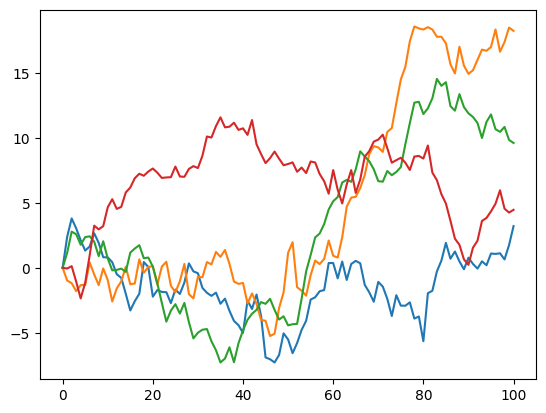

In [ ]:
#profe
import matplotlib.pyplot as plt
from random import gauss

def f():
    l = [0]
    M = 0
    for i in range(100):
        M += gauss(0, 1)
        l.append(M)
    return l

for i in range(4):
    l = f()
    plt.plot(l)

plt.show()

10 de septiembre de 2026


In [ ]:
from math import sqrt,exp
from random import gauss

def f(delta,T):
  o=sqrt(delta)
  x=10
  s=0
  t=0

  while t<T:
    w=o*gauss(1000,1)
    x=x+0.5*x*delta+0.1*x*w
    t=t+delta
    s=s+w

  z=10*exp((0.5-(0.1*0.1)/2)*T+0.1*w)

  return (x-z)*(x-z)

T=0.2
delta=0.005
print(f(delta,T))

3.700772574805674e+74


<>:50: SyntaxWarning: invalid escape sequence '\('
<>:50: SyntaxWarning: invalid escape sequence '\('
/tmp/ipykernel_899/1214035222.py:50: SyntaxWarning: invalid escape sequence '\('
  plt.title('Distribución del Error Cuadrático \((x - Z)^2\)')


Error cuadrático medio (MSE): 94.414166


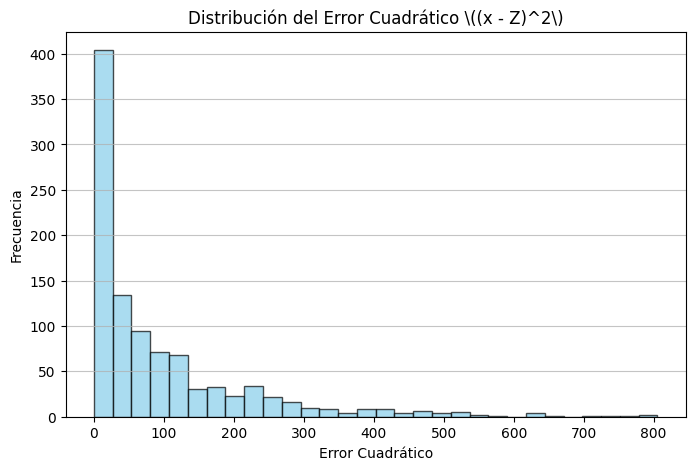

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from random import gauss

# Configuración para Jupyter Notebook
%matplotlib inline

def f(delta, T, N):
    """
    Simula N caminatas aleatorias y calcula el error cuadrático
    respecto a un valor teórico Z.
    """
    diff = np.zeros(N)
    exp = np.zeros(N) # Inicializado en el código original (aunque no se usa)

    for i in range(N):
        t = 0.0
        x = 0.0
        s = 0.0

        # Simulación del camino aleatorio
        while t < T:
            w = gauss(0, 1)  # Paso aleatorio con distribución normal estándar
            x = x + w        # Actualiza la posición
            s = s + w        # Actualiza la suma acumulada (no se usa después)
            t = t + delta    # Avanza el tiempo

        # Cálculo del valor teórico Z
        Z = np.sqrt((1 - np.exp(-2 * T)) / (2 * T + 1))

        # Cálculo del error cuadrático
        diff[i] = (x - Z) ** 2

    return diff, exp

# --- Parámetros de la simulación ---
delta = 0.01   # Tamaño del paso de tiempo
T = 1.0        # Tiempo total de simulación
N = 1000       # Número de simulaciones

# --- Ejecutar la simulación ---
diff, exp = f(delta, T, N)

# --- Resultados y visualización ---
print(f"Error cuadrático medio (MSE): {np.mean(diff):.6f}")

# Graficar la distribución de los errores
plt.figure(figsize=(8, 5))
plt.hist(diff, bins=30, edgecolor='black', alpha=0.7, color='skyblue')
plt.title('Distribución del Error Cuadrático \((x - Z)^2\)')
plt.xlabel('Error Cuadrático')
plt.ylabel('Frecuencia')
plt.grid(axis='y', alpha=0.75)
plt.show()

17 de septiembre de 2026

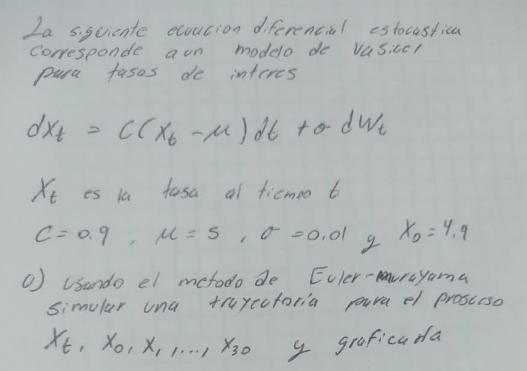


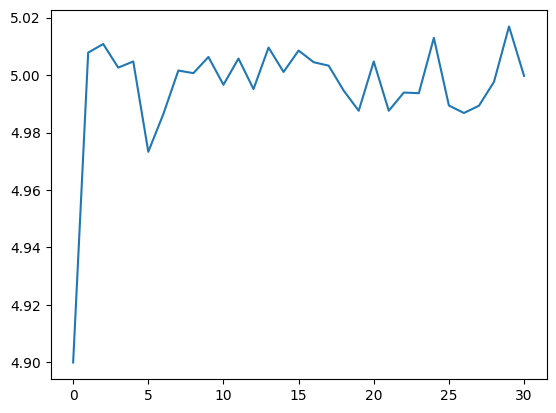

In [ ]:
from numpy.random import normal
import matplotlib.pyplot as plt

c=-0.9
mu=5
sigma=0.01
x0=4.9
dt=1
n=30

x=[x0]

for i in range(n):
    z=normal(0,1)
    xn=x[i]+c*(x[i]-mu)*dt+sigma*(dt**0.5)*z
    x.append(xn)

plt.plot(range(n+1),x)
plt.show()


b) crea un histograma para X_30

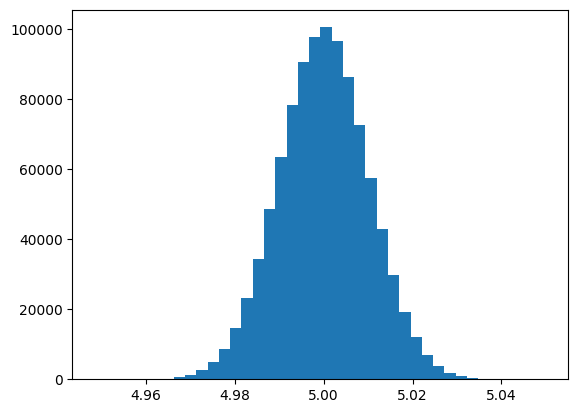

In [ ]:
from numpy.random import normal
import matplotlib.pyplot as plt

c=-0.9
mu=5
sigma=0.01
x0=4.9
dt=1
n=30
N=1000000

x30=[]

for j in range(N):
    x=x0

    for i in range(n):
        z=normal(0,1)
        x=x+c*(x-mu)*dt+sigma*(dt**0.5)*z

    x30.append(x)

plt.hist(x30,bins=40)
plt.show()

c) estimar la probabilidad de que X_34>4.95

In [ ]:
p=0

for j in range(N):
    x=x0

    for i in range(n):
        z=normal(0,1)
        x=x+c*(mu-x)*dt+sigma*(dt**0.5)*z

    if x>4.95:
        p=p+1

p=p/N

print("P(X30 > 4.95) =",p)

P(X30 > 4.95) = 0.0


d) estimar el tiempo en el que por primera vez X_t>mu

In [ ]:
from numpy.random import normal

c=0.9
mu=5
sigma=0.01
x0=4.9
dt=1
n=30
N=100000

tiempos=[]

for j in range(N):
    x=x0
    tiempo=0

    for i in range(1,n+1):
        z=normal(0,1)
        x=x+c*(mu-x)*dt+sigma*(dt**0.5)*z

        if x>mu:
            tiempo=i
            break

    tiempos.append(tiempo)

promedio=sum(tiempos)/N

print("Tiempo promedio de primera vez =",promedio)

Tiempo promedio de primera vez = 2.84597


todo junto hecho con IA

Trayectoria:
[4.9, 4.985289913149731, 4.9889304116221185, 4.995701179344747, 4.991335740532734, 4.987712957769531, 5.018432303333219, 5.01515895194077, 5.000766448363419, 4.983009520864726, 5.008088619505794, 5.0144016859360105, 5.02005152844269, 4.991904192068263, 5.0104028388662325, 4.99727533680193, 5.0042059356449755, 5.006238780387133, 4.97154106201114, 4.993378340939783, 4.997674894148296, 5.000915484046188, 5.001388875799455, 5.010251750635591, 4.985432133116041, 4.999445946974956, 4.9955300470501545, 5.0078791120937085, 5.007563254498895, 5.004562156819846, 4.992634912787987]


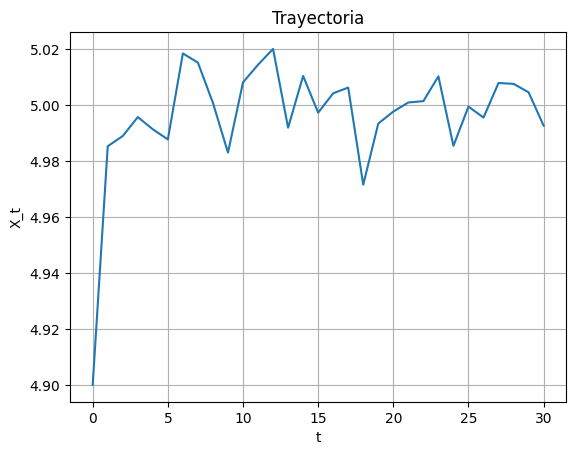

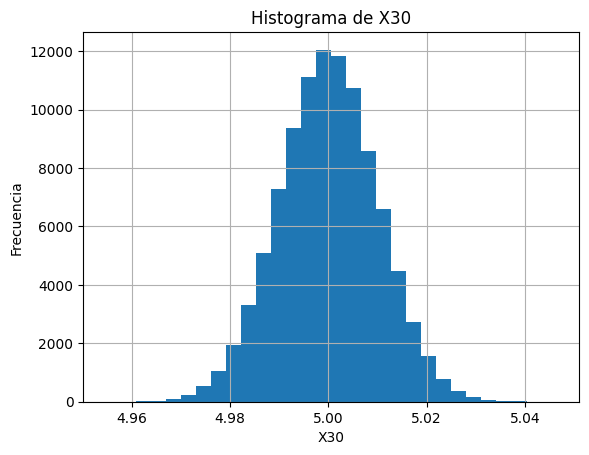

P(X30 > 4.95) = 1.0
Tiempo promedio de primera vez X_t > mu = 2.83521


In [ ]:
from numpy.random import normal
import matplotlib.pyplot as plt

c=0.9
mu=5
sigma=0.01
x0=4.9
dt=1
n=30
N=100000

# a) Una trayectoria

x=[x0]

for i in range(n):
    z=normal(0,1)
    xn=x[i]+c*(mu-x[i])*dt+sigma*(dt**0.5)*z
    x.append(xn)

print("Trayectoria:")
print(x)

plt.plot(range(31),x)
plt.xlabel("t")
plt.ylabel("X_t")
plt.title("Trayectoria")
plt.grid()
plt.show()


# b) Histograma de X30
# c) Probabilidad X30 > 4.95
# d) Primer tiempo X_t > mu

x30=[]
tiempos=[]

for j in range(N):
    x=x0
    tiempo=0

    for i in range(1,n+1):
        z=normal(0,1)
        x=x+c*(mu-x)*dt+sigma*(dt**0.5)*z

        if x>mu and tiempo==0:
            tiempo=i

    x30.append(x)
    tiempos.append(tiempo)

plt.hist(x30,bins=30)
plt.xlabel("X30")
plt.ylabel("Frecuencia")
plt.title("Histograma de X30")
plt.grid()
plt.show()

p=sum(1 for x in x30 if x>4.95)/N

print("P(X30 > 4.95) =",p)
print("Tiempo promedio de primera vez X_t > mu =",sum(tiempos)/N)

24 de septiembre

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import gamma;norm

def k(u):
  if abs(u)<1:
    return 1/2
  else:
    return 0
r=k(0.5)
r

0.5

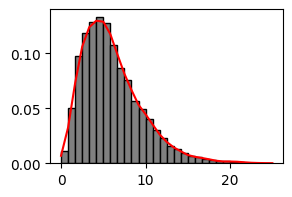

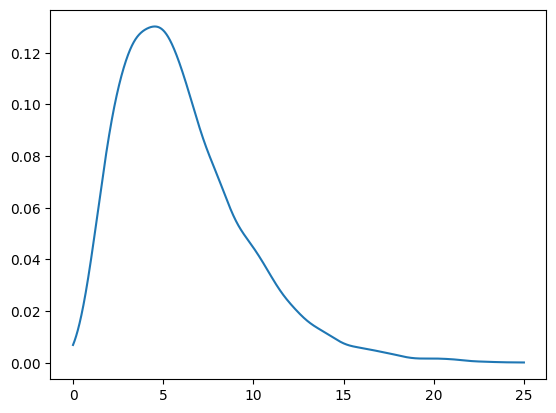

In [ ]:
import matplotlib.pyplot as plt
from scipy.stats import gamma, norm
from math import pi
import numpy as np

def k2(u):
    return (1/np.sqrt(2*pi))*np.exp(-u**2/2)

def k1(u):
    if abs(u)<1:
        return 1/2
    else:
        return 0

def est(x,h,l,k):
    suma=0
    n=len(l)
    for i in range(n):
        suma=suma+k((x-l[i])/h)
    return suma/(n*h)

a=3
b=2
N=10000
l=gamma.rvs(a,0,b,N)
b=[]
s=0
while s<25:
    b.append(s)
    s=s+25/30
h=1.06*np.std(l)/(N**0.2)
f=[]
for x in b:
    f.append(est(x,h,l,k2))
plt.figure(figsize=(3,2))
plt.hist(l,density=True,bins=b,color='grey',edgecolor='black')
plt.plot(b,f,color='red')
plt.show()

x=np.linspace(0,25,10000)
f=np.zeros(10000)
for i in range(10000):
    f[i]=est(x[i],h,l,k2)
plt.plot(x,f)
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

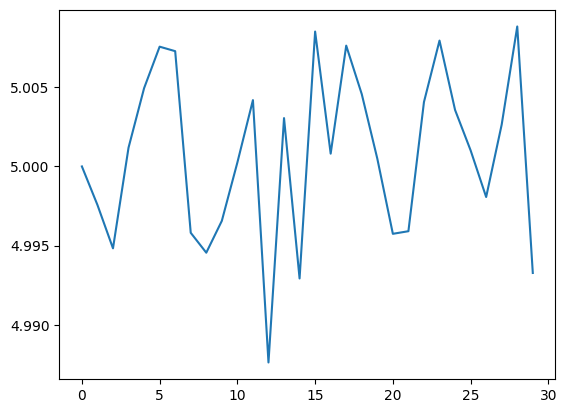

In [ ]:
from random import gauss
from math import sqrt
import numpy as np
import matplotlib.pyplot as plt

def tray(x0,c,u,o,delta,N):

  l=np.zeros(N)
  l[0]=x0
  oo=sqrt(delta)

  for i in range (N-1):
    x=l[i]
    t=0

    while t<1:
      w=oo*gauss(0,1)
      x=x+c*(x-u)*delta+o*w
      t=t+delta
    l[i+1]=x
  return l

def ver(l,c,u,o,delta):
  suma=0
  n=len(l)

  for i in range(n-1):
    x=l[i]

seed(43)
c=-0.9
u=5
o=0.01
x0=u
delta=0.01
N=30
l=tray(x0,c,u,o,delta,N)
plt.plot(l)
plt.show

In [ ]:
from random import gauss,seed
import numpy as np
from math import sqrt,log
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

def tray(x0,c,u,o,delta,N):
    l=np.zeros(N)
    l[0]=x0
    oo=sqrt(delta)
    for i in range(N-1):
        x=l[i]
        t=0
        while t<1:
            w=oo*gauss(0,1)
            x=x+c*(x-u)*delta+o*w
            t=t+delta
        l[i+1]=x
    return l

def ver(l,c,u,o,delta):
    suma=0
    oo=sqrt(delta)
    n=len(l)
    ns=10000
    for i in range(n-1):
        sim=np.zeros(ns)
        for j in range(ns):
            x=l[i]
            t=0
            while t<1:
                w=oo*gauss(0,1)
                x=x+c*(x-u)*delta+o*w
                t=t+delta
            sim[j]=x
        pdf=gaussian_kde(sim)
        valor=pdf(l[i+1])[0]
        suma=suma+log(valor)
    return suma

seed(43)
c=-.6
u=5
o=0.01
x0=u
delta=0.01
N=30
l = tray(x0, c, u, o, delta, N)
L=ver(l,c,u,o,delta)
print(L)

104.00922777238333


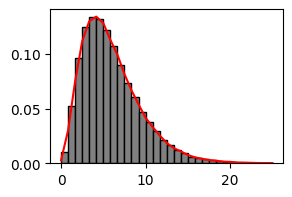

In [ ]:
import matplotlib.pyplot as plt
from scipy.stats import gamma,norm
from math import pi
import numpy as np
from scipy.stats import gaussian_kde
a=3
b=2
N=100000
l=gamma.rvs(a,0,b,N)
b=[]
s=0
while s<25:
    b.append(s)
    s=s+25/30
h=1.06*np.std(l)/(N**0.2)
pdf=gaussian_kde(l)
f=[]
for x in b:
    f.append(pdf(x)[0])
plt.figure(figsize=(3,2))
plt.hist(l,density=1,bins=b,color='grey',edgecolor='black')
plt.plot(b,f,color='red')
plt.show()

29 de septiembre de 2026

In [ ]:
from random import random
from math import sqrt
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import Nelder-Mead
from scipy.stats import gaussian_kde



def f(t,delta,ns):
  o=sqrt(delta)
  n=len(t)
  suma=0

  for i in range(n):
    val_sim=np.zeros(ns)

    for j in range(ns):
      x=1
      t0=0

      while t0<1:
        w=o*gauss(0,1)
        x=x+(x-1)*delta*w
        t0=t0+delta
        val_sim[j]=x

    pdf=gaussian_kde(val_sim)
    valor=pdf([t[i]])[0]

    if valor<1e-200:
      valor=1e-200

SyntaxError: invalid syntax (3295384955.py, line 5)

# ejercicios para 1er examen


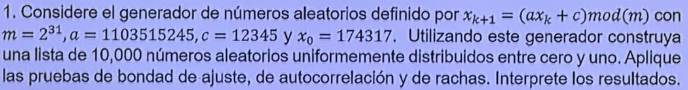

In [ ]:
from random import seed
import numpy as np
from scipy.stats import chi2, norm

# Parámetros
m = 2**31
a = 1103515245
c = 12345
x0 = 174317
N = 10000

# Generación de números
x = np.zeros(N, dtype=np.int64)
u = np.zeros(N)
x[0] = x0
u[0] = x[0] / m

for i in range(1, N):
    x[i] = (a * x[i-1] + c) % m
    u[i] = x[i] / m

# --- 1. Prueba de Bondad de Ajuste (Chi-cuadrada) ---
k = 10
frec_obs, _ = np.histogram(u, bins=k, range=(0, 1))
frec_esp = N / k
chi2_stat = np.sum((frec_obs - frec_esp)**2 / frec_esp)
gl = k - 1
p_chi2 = 1 - chi2.cdf(chi2_stat, gl)

# --- 2. Prueba de Autocorrelación (Lag=1) ---
lag = 1
media = np.mean(u)
varianza = np.var(u)
num = np.sum((u[:N-lag] - media) * (u[lag:] - media))
den = (N - lag) * varianza
rho = num / den
z_auto = rho * np.sqrt(N)
p_auto = 2 * (1 - norm.cdf(abs(z_auto)))

# --- 3. Prueba de Rachas ---
mediana = np.median(u)
secuencia = u > mediana
rachas = 1
for i in range(1, N):
    if secuencia[i] != secuencia[i-1]:
        rachas += 1
n1 = np.sum(secuencia)
n0 = N - n1
media_rachas = (2 * n1 * n0) / N + 1
var_rachas = (2 * n1 * n0 * (2 * n1 * n0 - N)) / (N**2 * (N - 1))
z_rachas = (rachas - media_rachas) / np.sqrt(var_rachas)
p_rachas = 2 * (1 - norm.cdf(abs(z_rachas)))

# --- Impresión de resultados ---
print("--- RESULTADOS ---")
print(f"1. Chi-cuadrada: Estadístico = {chi2_stat:.4f}, Valor p = {p_chi2:.4f}")
print(f"2. Autocorrelación (Lag 1): rho = {rho:.4f}, Estadístico Z = {z_auto:.4f}, Valor p = {p_auto:.4f}")
print(f"3. Rachas: Rachas obs = {rachas}, Z = {z_rachas:.4f}, Valor p = {p_rachas:.4f}")

--- RESULTADOS ---
1. Chi-cuadrada: Estadístico = 3.9680, Valor p = 0.9135
2. Autocorrelación (Lag 1): rho = -0.0059, Estadístico Z = -0.5930, Valor p = 0.5532
3. Rachas: Rachas obs = 5046, Z = 0.9000, Valor p = 0.3681


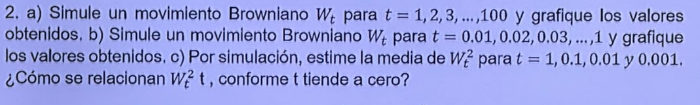

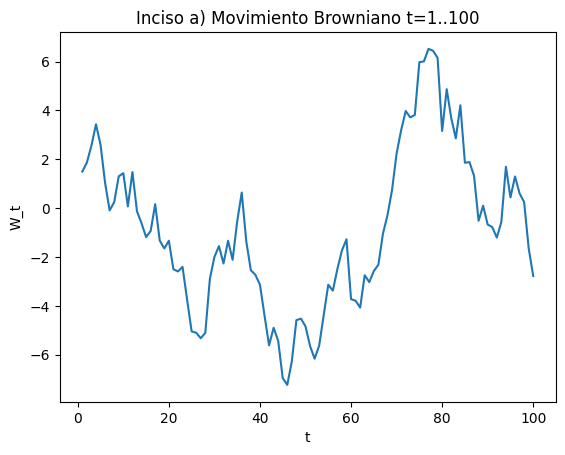

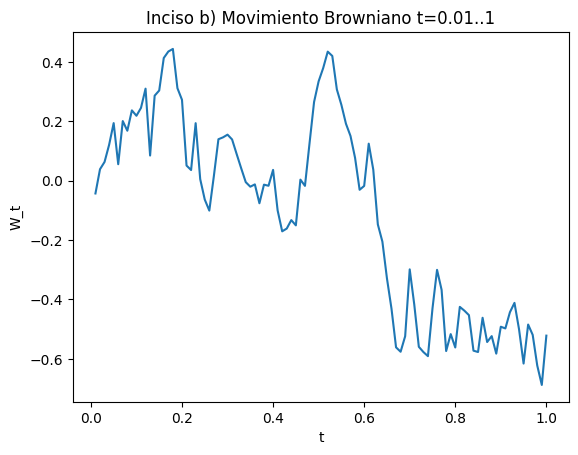

--- Inciso c) Estimación de E[W_t^2] ---
t        | E[W_t^2] estimada    | Valor teórico (t) 
--------------------------------------------------
1        | 0.993085             | 1                 
0.1      | 0.099230             | 0.1               
0.01     | 0.009947             | 0.01              
0.001    | 0.001008             | 0.001             

--- Relación conforme t tiende a cero ---
Conforme t -> 0, E[W_t^2] también tiende a 0.


In [ ]:
from random import seed, gauss
import numpy as np
import matplotlib.pyplot as plt

seed(43) # Semilla fija para reproducibilidad

# --- Inciso a) Simular W_t para t = 1, 2, ..., 100 y graficar ---
N_a = 100
W_a = np.zeros(N_a)
W_a[0] = gauss(0, 1) # W_1
for i in range(1, N_a):
    W_a[i] = W_a[i-1] + gauss(0, 1) # delta=1

# Gráfica inciso a)
plt.figure()
plt.plot(range(1, N_a + 1), W_a)
plt.title('Inciso a) Movimiento Browniano t=1..100')
plt.xlabel('t')
plt.ylabel('W_t')
plt.show()

# --- Inciso b) Simular W_t para t = 0.01, 0.02, ..., 1 y graficar ---
delta_b = 0.01
N_b = int(1 / delta_b) # 100 pasos
W_b = np.zeros(N_b)
W_b[0] = np.sqrt(delta_b) * gauss(0, 1) # W_0.01
for i in range(1, N_b):
    W_b[i] = W_b[i-1] + np.sqrt(delta_b) * gauss(0, 1)

# Gráfica inciso b)
plt.figure()
plt.plot(np.linspace(delta_b, 1, N_b), W_b)
plt.title('Inciso b) Movimiento Browniano t=0.01..1')
plt.xlabel('t')
plt.ylabel('W_t')
plt.show()

# --- Inciso c) Estimar E[W_t^2] por simulación ---
M = 10000 # Número de simulaciones
tiempos = [1, 0.1, 0.01, 0.001]

print("--- Inciso c) Estimación de E[W_t^2] ---")
print(f"{'t':<8} | {'E[W_t^2] estimada':<20} | {'Valor teórico (t)':<18}")
print("-" * 50)

for t in tiempos:
    delta = t / 100 # Usamos 100 pasos para llegar a t
    suma_cuadrados = 0
    for _ in range(M):
        w = 0
        for _ in range(100):
            w += np.sqrt(delta) * gauss(0, 1)
        suma_cuadrados += w**2
    esperanza_estimada = suma_cuadrados / M
    print(f"{t:<8} | {esperanza_estimada:<20.6f} | {t:<18}")

print("\n--- Relación conforme t tiende a cero ---")
print("Conforme t -> 0, E[W_t^2] también tiende a 0.")

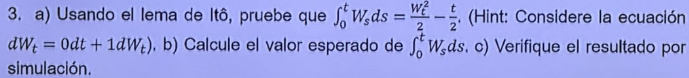

In [ ]:
from random import seed, gauss
import numpy as np

seed(43)

# Parámetros
t_final = 1.0
n_pasos = 1000
delta = t_final / n_pasos
M = 10000  # Número de simulaciones

suma_integrales = 0

for _ in range(M):
    w = 0
    integral = 0
    for _ in range(n_pasos):
        w += np.sqrt(delta) * gauss(0, 1)
        integral += w * delta  # Suma de Riemann
    suma_integrales += integral

# Estimación del valor esperado
esperanza_estimada = suma_integrales / M

print(f"Valor teórico E[∫ W_s ds] = 0.0")
print(f"Valor simulado E[∫ W_s ds] = {esperanza_estimada:.6f}")

Valor teórico E[∫ W_s ds] = 0.0
Valor simulado E[∫ W_s ds] = -0.004563


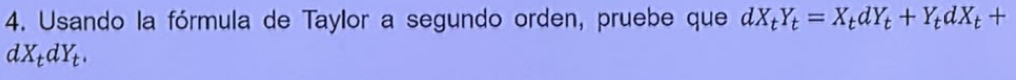

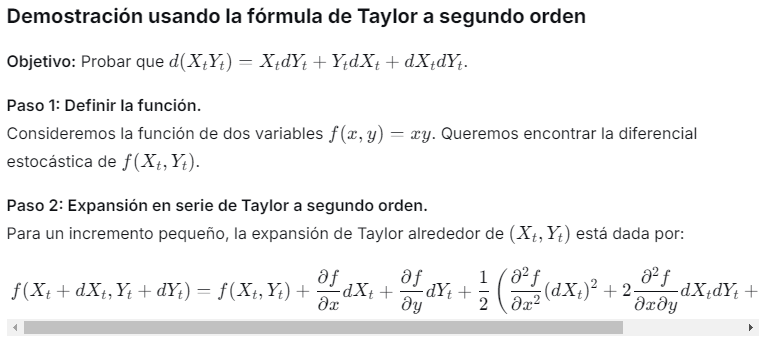

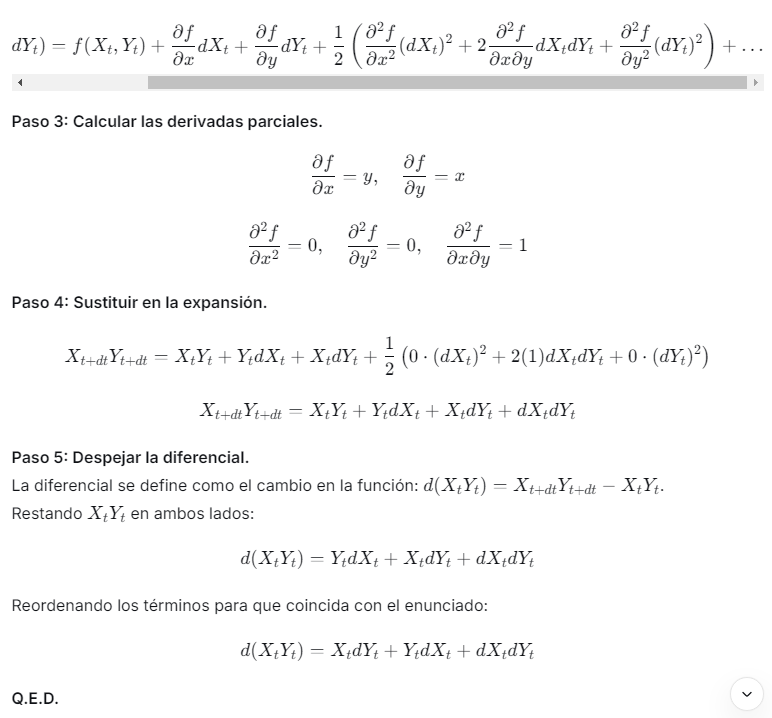

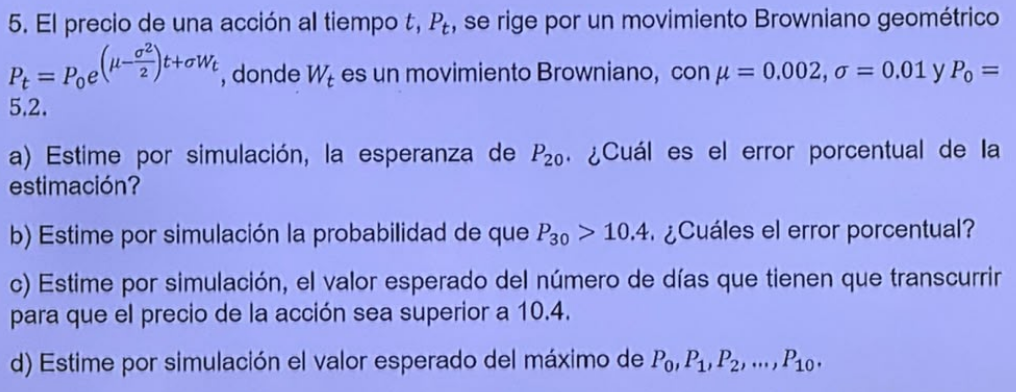

In [ ]:
from random import seed, gauss
import numpy as np

seed(43)

mu = 0.002
sigma = 0.01
P0 = 5.2
M = 100000

# a)
t_a = 20
Z_a = np.array([gauss(0, 1) for _ in range(M)])
P_20 = P0 * np.exp((mu - sigma**2 / 2) * t_a + sigma * np.sqrt(t_a) * Z_a)
esperanza_P20 = np.mean(P_20)
esperanza_teorica_a = P0 * np.exp(mu * t_a)
error_a = abs((esperanza_P20 - esperanza_teorica_a) / esperanza_teorica_a) * 100
print(f"a) Esperanza P_20: {esperanza_P20:.6f}, Error: {error_a:.4f}%")

# b)
t_b = 30
Z_b = np.array([gauss(0, 1) for _ in range(M)])
P_30 = P0 * np.exp((mu - sigma**2 / 2) * t_b + sigma * np.sqrt(t_b) * Z_b)
prob_estimada = np.mean(P_30 > 10.4)
error_b = np.sqrt(prob_estimada * (1 - prob_estimada) / M) * 100
print(f"b) Probabilidad P_30 > 10.4: {prob_estimada:.6f}, Error: {error_b:.4f}%")

# c)
umbral = 10.4
dias_espera = []
for _ in range(M):
    P = P0
    dia = 0
    while P <= umbral:
        P = P * np.exp((mu - sigma**2 / 2) * 1 + sigma * gauss(0, 1))
        dia += 1
    dias_espera.append(dia)
esperanza_dias = np.mean(dias_espera)
error_c = np.std(dias_espera) / np.sqrt(M) / esperanza_dias * 100
print(f"c) Días esperados: {esperanza_dias:.4f}, Error: {error_c:.4f}%")

# d)
t_d = 10
maximos = []
for _ in range(M):
    P_tray = [P0]
    for _ in range(t_d):
        P_tray.append(P_tray[-1] * np.exp((mu - sigma**2 / 2) * 1 + sigma * gauss(0, 1)))
    maximos.append(max(P_tray))
esperanza_max = np.mean(maximos)
error_d = np.std(maximos) / np.sqrt(M) / esperanza_max * 100
print(f"d) Máximo esperado: {esperanza_max:.6f}, Error: {error_d:.4f}%")

a) Esperanza P_20: 5.412597, Error: 0.0070%
b) Probabilidad P_30 > 10.4: 0.000000, Error: 0.0000%
c) Días esperados: 358.9880, Error: 0.0854%
d) Máximo esperado: 5.367300, Error: 0.0074%


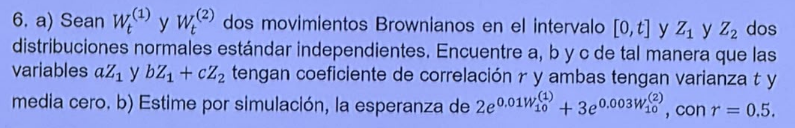

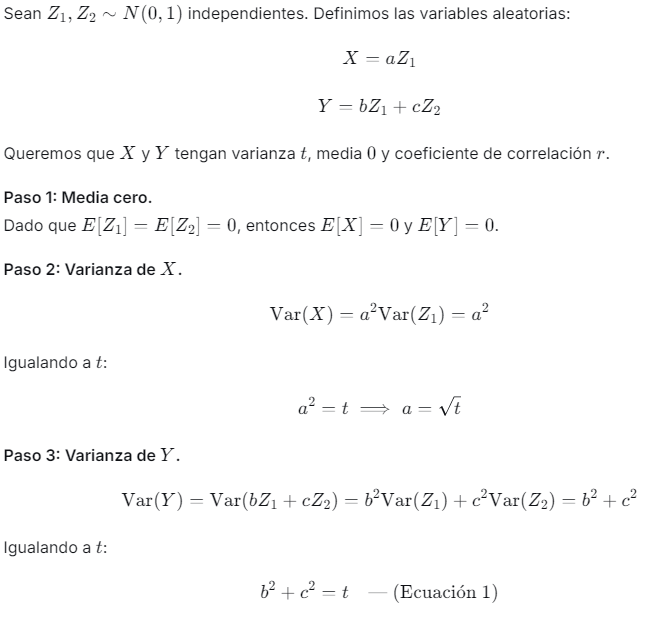

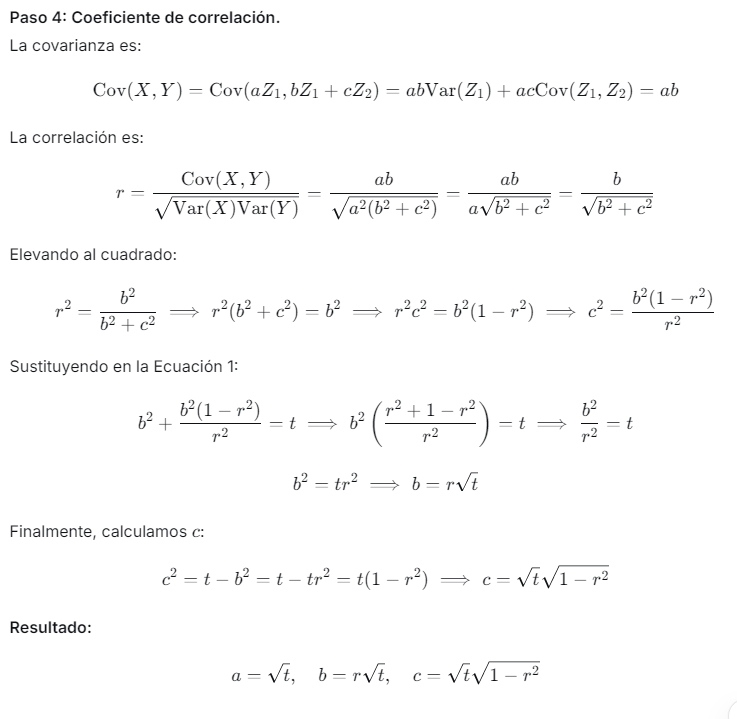

In [ ]:
from random import seed, gauss
import numpy as np

seed(43)

M = 100000

# Parámetros
t = 10
r = 0.5

# Constantes para generar las normales correlacionadas
a = np.sqrt(t)
b = r * np.sqrt(t)
c = np.sqrt(t) * np.sqrt(1 - r**2)

# Simulación
Z1 = np.array([gauss(0, 1) for _ in range(M)])
Z2 = np.array([gauss(0, 1) for _ in range(M)])

W1 = a * Z1
W2 = b * Z1 + c * Z2

resultado = 2 * np.exp(0.01 * W1) + 3 * np.exp(0.003 * W2)
esperanza = np.mean(resultado)

print(f"Esperanza estimada: {esperanza:.6f}")

Esperanza estimada: 5.001330


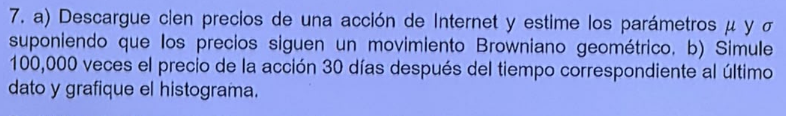

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from random import seed, gauss

# ==========================================
# a) Estimación de parámetros mu y sigma
# ==========================================
# NOTA: Reemplaza 'precios.csv' por el nombre real de tu archivo.
# Asumo que el archivo tiene una columna llamada 'Precio' o similar.
# Si tu archivo tiene otra estructura, ajusta la lectura.

# Ejemplo de lectura (descomenta y ajusta según tu archivo):
# df = pd.read_csv('precios.csv')
# P = df['Precio'].values
# n = len(P)

# --- DATOS DE EJEMPLO (BORRAR Y USAR TUS DATOS REALES) ---
# He generado datos ficticios solo para que el código se pueda ejecutar y veas el formato.
np.random.seed(43)
n = 100
P = 100 * np.exp(np.cumsum(0.0005 + 0.02 * np.random.randn(n)))
# --------------------------------------------------------

# Cálculo de rendimientos logarítmicos
R = np.log(P[1:] / P[:-1])
dt = 1  # Asumimos 1 día entre precios

# Estimadores de máxima verosimilitud para GBM
mu_est = np.mean(R) / dt + (np.var(R) / dt) / 2
sigma_est = np.sqrt(np.var(R) / dt)

print("--- Inciso a) ---")
print(f"mu estimado: {mu_est:.6f}")
print(f"sigma estimado: {sigma_est:.6f}")


# ==========================================
# b) Simulación de 100,000 precios a 30 días
# ==========================================
seed(43)
M = 100000
T = 30
P0 = P[-1]  # Último precio de la serie

# Generación de precios finales a 30 días
Z = np.array([gauss(0, 1) for _ in range(M)])
P_T = P0 * np.exp((mu_est - sigma_est**2 / 2) * T + sigma_est * np.sqrt(T) * Z)

# Histograma
plt.figure()
plt.hist(P_T, bins=50, density=True, color='grey', edgecolor='black')
plt.title('Histograma de Precios Simulados a 30 días')
plt.xlabel('Precio')
plt.ylabel('Densidad')
plt.show()

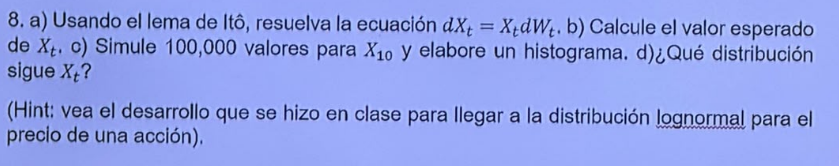

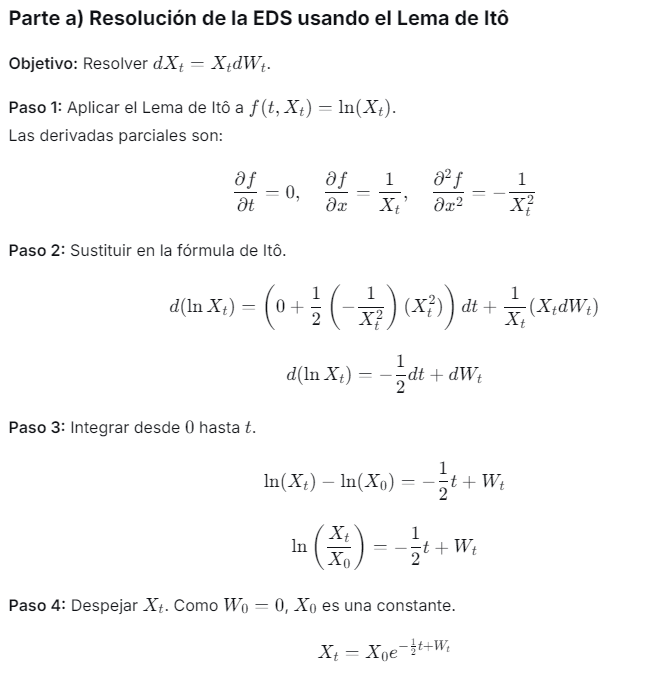

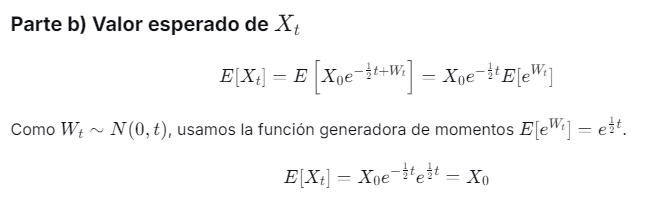

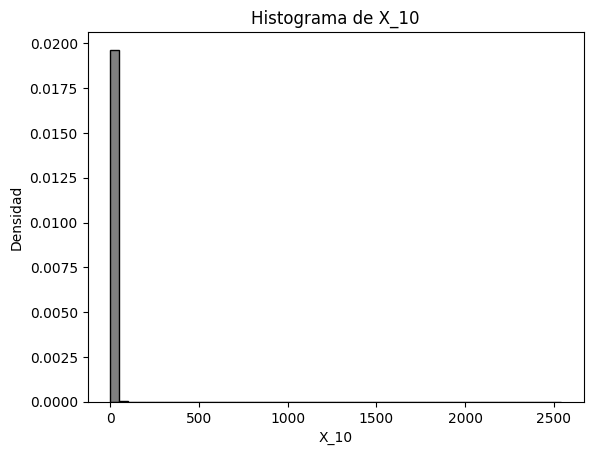

In [ ]:
from random import seed, gauss
import numpy as np
import matplotlib.pyplot as plt

seed(43)

M = 100000
t = 10
X0 = 1

Z = np.array([gauss(0, 1) for _ in range(M)])
W_t = np.sqrt(t) * Z
X_10 = X0 * np.exp(-0.5 * t + W_t)

plt.figure()
plt.hist(X_10, bins=50, density=True, color='grey', edgecolor='black')
plt.title('Histograma de X_10')
plt.xlabel('X_10')
plt.ylabel('Densidad')
plt.show()